# TP4 · Fêtes et consommation au Sénégal
**Python avancé, L3 Intelligence Artificielle, ISM** · Hamze Abdoulkarim Aden · Enseignant : Elias BADJI

> **Données fictives.** Toutes les données sont simulées à des fins pédagogiques. Elles ne décrivent pas le comportement réel des Sénégalais ni d'aucune communauté religieuse, et aucune conclusion sur une communauté n'est tirée de ce travail.

**Les quatre questions de la direction**
1. **Mesurer** : quels produits s'envolent avant chaque fête, de combien, et dans quelles villes ?
2. **Prévoir** : peut-on prévoir la demande de 2025 avec un an d'avance ?
3. **Comprendre** : quels ménages s'endettent après une fête, et pourquoi ?
4. **Agir** : quelles quantités prévoir pour les fêtes de 2026 ?

**Sommaire** : 0. Configuration · 1. Audit et nettoyage · 2. Variables d'événement · 3. Effet des fêtes · Bonus promotions · 4. Prévision à un an · Bonus quantiles · 5. Endettement et équité · 6. Profils de dépense · 7. Plan 2026

## Partie 0 · Configuration

In [1]:
# === Imports ===
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

# === Interrupteur : False = recharger ce qui est déjà sauvegardé, True = tout recalculer ===
RECALCULER = False

# === Reproductibilité : la même graine partout ===
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# === Chemins : le notebook est dans notebooks/, la racine du projet est le dossier parent ===
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DOSSIER_RAW = RACINE / "data" / "raw"
DOSSIER_PROCESSED = RACINE / "data" / "processed"
DOSSIER_MODELES = RACINE / "models"
DOSSIER_RAPPORTS = RACINE / "reports"
DOSSIER_FIGURES = DOSSIER_RAPPORTS / "figures"

# Ces dossiers sont ignorés par git : on les recrée s'ils n'existent pas (après un clone par exemple)
for dossier in [DOSSIER_PROCESSED, DOSSIER_MODELES, DOSSIER_FIGURES]:
    dossier.mkdir(parents=True, exist_ok=True)

# === Affichage ===
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100


# === Fonctions utilitaires ===
def sauver_figure(fig, nom):
    """Enregistre une figure en PNG dans reports/figures/ (nom sans extension)."""
    chemin = DOSSIER_FIGURES / f"{nom}.png"
    fig.savefig(chemin, dpi=150, bbox_inches="tight")
    print("Figure enregistrée :", chemin.name)


def chemin_parquet(nom):
    """Chemin d'un fichier intermédiaire dans data/processed/."""
    return DOSSIER_PROCESSED / f"{nom}.parquet"


def chemin_modele(nom):
    """Chemin d'un modèle sauvegardé avec joblib dans models/."""
    return DOSSIER_MODELES / f"{nom}.joblib"


def peut_recharger(*chemins):
    """True si RECALCULER vaut False ET que tous les fichiers demandés existent déjà."""
    return (not RECALCULER) and all(Path(c).exists() for c in chemins)


print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("Racine du projet :", RACINE)
print("Fichiers bruts :", sorted(p.name for p in DOSSIER_RAW.glob("*.csv")))

pandas 3.0.6 | scikit-learn 1.9.1
Racine du projet : c:\Users\User\Desktop\L3S5\Python avance\TP4\fetes-consommation-senegal
Fichiers bruts : ['calendrier_evenements.csv', 'categories.csv', 'enquete_menages.csv', 'magasins.csv', 'ventes_journalieres.csv']


## Partie 1 · Audit et nettoyage

### 1.1 Chargement des données

In [2]:
# Ventes : dates parsées, textes répétitifs en category ; les colonnes numériques sont laissées à pandas
# (si l'une contient du texte, elle ne sera pas numérique, et ce sera un défaut à traiter)
ventes_brutes = pd.read_csv(
    DOSSIER_RAW / "ventes_journalieres.csv",
    parse_dates=["date"],
    dtype={"magasin_id": "category", "categorie": "category"},
)

# Tables de référence
magasins = pd.read_csv(DOSSIER_RAW / "magasins.csv", parse_dates=["date_ouverture"])
categories = pd.read_csv(DOSSIER_RAW / "categories.csv")
calendrier = pd.read_csv(DOSSIER_RAW / "calendrier_evenements.csv", parse_dates=["date_debut", "date_fin"])

print("Ventes :", ventes_brutes.shape, "| Magasins :", magasins.shape,
      "| Catégories :", categories.shape, "| Calendrier :", calendrier.shape)
ventes_brutes.info(memory_usage="deep")
ventes_brutes.head()

Ventes : (530790, 8) | Magasins : (10, 6) | Catégories : (15, 4) | Calendrier : (103, 7)
<class 'pandas.DataFrame'>
RangeIndex: 530790 entries, 0 to 530789
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   date                   530790 non-null  datetime64[us]
 1   magasin_id             530790 non-null  category      
 2   categorie              530790 non-null  category      
 3   quantite               529730 non-null  float64       
 4   prix_unitaire_fcfa     530790 non-null  float64       
 5   promo                  530790 non-null  int64         
 6   part_paiement_mobile   530790 non-null  float64       
 7   chiffre_affaires_fcfa  529730 non-null  float64       
dtypes: category(2), datetime64[us](1), float64(4), int64(1)
memory usage: 25.3 MB


,date,magasin_id,categorie,quantite,prix_unitaire_fcfa,promo,part_paiement_mobile,chiffre_affaires_fcfa
0,2016-01-01,M01,arachide_bouye,31.0,1175.0,0,0.034,36425.0
1,2016-01-01,M01,beaute_coiffure,46.0,2500.0,0,0.018,115000.0
2,2016-01-01,M01,betail_mouton,0.0,89500.0,0,0.000,0.0
3,2016-01-01,M01,boissons,265.0,500.0,0,0.000,132500.0
4,2016-01-01,M01,cereales_mil,56.0,375.0,0,0.008,21000.0


In [3]:
print("Type de la colonne date :", ventes_brutes["date"].dtype)
print("Période couverte :", ventes_brutes["date"].min().date(), "->", ventes_brutes["date"].max().date())

print("\nLignes par magasin :")
print(ventes_brutes["magasin_id"].value_counts().sort_index().to_string())

print("\nCatégories trouvées dans les ventes (avec effectifs) :")
print(ventes_brutes["categorie"].value_counts().sort_index().to_string())
print("\nCatégories officielles (categories.csv) :", categories["categorie"].tolist())

ventes_brutes.describe().T

Type de la colonne date : datetime64[us]
Période couverte : 2016-01-01 -> 2025-12-31

Lignes par magasin :
magasin_id
M01    54837
M02    54826
M03    54703
M04    54826
M05    54825
M06    49332
M07    54825
M08    54822
M09    54822
M10    42972

Catégories trouvées dans les ventes (avec effectifs) :
categorie
Arachide_bouye             9
BEAUTE_COIFFURE           17
BETAIL_MOUTON             13
Beaute_coiffure           15
Boissons                  14
CEREALES_MIL              10
CREDIT_MOBILE              9
DATTES                    11
Dattes                    12
HUILE                      8
Huile                     13
JOUETS_CADEAUX            12
Jouets_cadeaux            13
LAIT                      11
Oignons                   13
RIZ                       15
Riz                        9
SUCRE                     10
Sucre                     10
TISSUS_HABILLEMENT         7
Tissus_habillement        11
VOLAILLE                  12
arachide_bouye         35348
arachide_bouye     

,count,mean,min,25%,50%,75%,max,std
date,530790,2021-02-17 22:19:46.882948,2016-01-01 00:00:00,2018-09-26 00:00:00,2021-02-26 00:00:00,2023-07-31 00:00:00,2025-12-31 00:00:00,NaN
quantite,529730.0,119.111982,-607.0,20.0,64.0,178.0,51000.0,186.312986
prix_unitaire_fcfa,530790.0,10095.579796,250.0,550.0,1400.0,2875.0,204000.0,31227.265444
promo,530790.0,0.042791,0.0,0.0,0.0,0.0,1.0,0.202386
part_paiement_mobile,530790.0,0.153309,0.0,0.042,0.088,0.232,0.708,0.152946
chiffre_affaires_fcfa,529730.0,118347.579144,-349350.0,33350.0,85625.0,159075.0,34540000.0,165548.204541


### 1.2 Audit : mesure des défauts (aucune correction à ce stade)

In [4]:
# Catégories mal saisies
import unicodedata

CLE = ["date", "magasin_id", "categorie"]          # clé d'une ligne de vente
CATS_OFFICIELLES = set(categories["categorie"])


def normaliser_categorie(texte):
    """Ramène un libellé au format officiel : sans accents, minuscules, sans espaces autour, '_' comme séparateur."""
    texte = unicodedata.normalize("NFKD", str(texte)).encode("ascii", "ignore").decode("ascii")
    return texte.strip().lower().replace(" ", "_").replace("-", "_")


# On travaille sur les libellés distincts (quelques dizaines), pas sur les 530 000 lignes
correspondance = {lib: normaliser_categorie(lib) for lib in ventes_brutes["categorie"].cat.categories}
mal_saisis = {lib: norm for lib, norm in correspondance.items() if lib not in CATS_OFFICIELLES}
irrecuperables = {lib: norm for lib, norm in mal_saisis.items() if norm not in CATS_OFFICIELLES}

nb_lignes_mal_saisies = ventes_brutes["categorie"].isin(list(mal_saisis)).sum()
print(f"{len(mal_saisis)} libellés mal saisis, présents sur {nb_lignes_mal_saisies} lignes")
print("Libellés non récupérables après normalisation :", irrecuperables)

# Copie de travail de l'audit, avec les catégories normalisées
ventes_audit = ventes_brutes.copy()
ventes_audit["categorie"] = ventes_audit["categorie"].map(correspondance).astype("category")
print("Catégories après normalisation :", ventes_audit["categorie"].nunique())

45 libellés mal saisis, présents sur 530 lignes
Libellés non récupérables après normalisation : {}
Catégories après normalisation : 15


In [5]:
# Doublons
nb_doublons_exacts = ventes_audit.duplicated().sum()
nb_doublons_cle = ventes_audit.duplicated(subset=CLE).sum()
print("Doublons exacts (lignes entièrement identiques) :", nb_doublons_exacts)
print("Doublons sur la clé (date, magasin, catégorie)  :", nb_doublons_cle)
print("  dont doublons de clé avec des valeurs différentes :", nb_doublons_cle - nb_doublons_exacts)

print("\nDoublons de clé par magasin :")
print(ventes_audit[ventes_audit.duplicated(subset=CLE)]["magasin_id"].value_counts().sort_index().to_string())

# Exemple : quelques groupes de doublons côte à côte
masque_dup = ventes_audit.duplicated(subset=CLE, keep=False)
ventes_audit[masque_dup].sort_values(CLE).head(8)

Doublons exacts (lignes entièrement identiques) : 300
Doublons sur la clé (date, magasin, catégorie)  : 300
  dont doublons de clé avec des valeurs différentes : 0

Doublons de clé par magasin :
magasin_id
M01    42
M02    31
M03    28
M04    31
M05    30
M06    27
M07    30
M08    27
M09    27
M10    27


,date,magasin_id,categorie,quantite,prix_unitaire_fcfa,promo,part_paiement_mobile,chiffre_affaires_fcfa
2627,2016-01-22,M09,betail_mouton,0.0,89000.0,0,0.084,0.0
2628,2016-01-22,M09,betail_mouton,0.0,89000.0,0,0.084,0.0
3766,2016-02-01,M04,arachide_bouye,20.0,1200.0,0,0.006,24000.0
3767,2016-02-01,M04,arachide_bouye,20.0,1200.0,0,0.006,24000.0
4741,2016-02-09,M04,volaille,14.0,2400.0,0,0.027,33600.0
4742,2016-02-09,M04,volaille,14.0,2400.0,0,0.027,33600.0
6733,2016-02-26,M01,oignons,147.0,300.0,0,0.024,44100.0
6734,2016-02-26,M01,oignons,147.0,300.0,0,0.024,44100.0


In [6]:
# Valeurs manquantes
manquants = ventes_audit.isna().sum()
print("Valeurs manquantes :\n", manquants[manquants > 0].to_string())
memes_lignes = (ventes_audit["quantite"].isna() == ventes_audit["chiffre_affaires_fcfa"].isna()).all()
print("quantite et chiffre_affaires manquent sur les mêmes lignes :", memes_lignes)
print("Lignes manquantes par année :",
      ventes_audit.loc[ventes_audit["quantite"].isna(), "date"].dt.year.value_counts().sort_index().to_dict())

# Quantités négatives
negatifs = ventes_audit[ventes_audit["quantite"] < 0]
print("\nQuantités négatives :", len(negatifs))
print("Par catégorie :", negatifs["categorie"].value_counts().head(5).to_dict())
print("Quantiles des valeurs négatives :", negatifs["quantite"].quantile([0, 0.5, 1]).to_dict())

# Cohérence : chiffre d'affaires = quantité x prix ?
ecart_ca = (ventes_audit["chiffre_affaires_fcfa"]
            - ventes_audit["quantite"] * ventes_audit["prix_unitaire_fcfa"]).abs()
print("\nLignes où CA != quantité x prix (écart > 1 FCFA) :", (ecart_ca > 1).sum())

# Bornes des autres colonnes
print("Valeurs de promo :", sorted(ventes_audit["promo"].unique()))
print("part_paiement_mobile hors de [0, 1] :",
      (~ventes_audit["part_paiement_mobile"].between(0, 1)).sum())

Valeurs manquantes :
 quantite                 1060
chiffre_affaires_fcfa    1060
quantite et chiffre_affaires manquent sur les mêmes lignes : True
Lignes manquantes par année : {2016: 89, 2017: 83, 2018: 117, 2019: 89, 2020: 114, 2021: 111, 2022: 126, 2023: 124, 2024: 93, 2025: 114}

Quantités négatives : 29
Par catégorie : {'huile': 4, 'jouets_cadeaux': 4, 'cereales_mil': 3, 'lait': 3, 'riz': 3}
Quantiles des valeurs négatives : {0.0: -607.0, 0.5: -62.0, 1.0: -5.0}

Lignes où CA != quantité x prix (écart > 1 FCFA) : 0
Valeurs de promo : [np.int64(0), np.int64(1)]
part_paiement_mobile hors de [0, 1] : 0


In [7]:
# Valeurs aberrantes

# Quantités : rapport à la valeur du 99e percentile de chaque couple magasin x catégorie
p99 = (ventes_audit.groupby(["magasin_id", "categorie"], observed=True)["quantite"]
       .transform(lambda s: s.quantile(0.99)))
ventes_audit["ratio_p99"] = ventes_audit["quantite"] / p99

print("Nombre de lignes au-dessus de k fois le p99 :")
for k in [2, 3, 5, 10, 20]:
    print(f"  > {k:>2} x p99 : {(ventes_audit['ratio_p99'] > k).sum()}")

# Les 15 plus gros rapports, avec la date pour vérifier qu'il ne s'agit pas d'un pic de fête
display(ventes_audit.sort_values("ratio_p99", ascending=False)
        .head(15)[CLE + ["quantite", "ratio_p99", "prix_unitaire_fcfa", "promo"]])

# Prix : rapport au prix médian de la catégorie la même année
prix_median = (ventes_audit.groupby(["categorie", ventes_audit["date"].dt.year], observed=True)
               ["prix_unitaire_fcfa"].transform("median"))
ratio_prix = ventes_audit["prix_unitaire_fcfa"] / prix_median
print("Prix > 3x ou < 1/3 du prix médian (catégorie, année) :", ((ratio_prix > 3) | (ratio_prix < 1 / 3)).sum())
print("Rapport de prix min / max :", round(ratio_prix.min(), 2), "/", round(ratio_prix.max(), 2))

Nombre de lignes au-dessus de k fois le p99 :
  >  2 x p99 : 191
  >  3 x p99 : 52
  >  5 x p99 : 36
  > 10 x p99 : 36
  > 20 x p99 : 35


,date,magasin_id,categorie,quantite,ratio_p99,prix_unitaire_fcfa,promo
130176,2018-09-09,M10,riz,42900.0,92.095659,300.0,0
389325,2023-06-03,M04,riz,51000.0,74.097751,400.0,0
516192,2025-09-25,M08,cereales_mil,6300.0,68.078669,400.0,1
462199,2024-09-30,M10,huile,10700.0,67.541977,1550.0,0
117139,2018-06-15,M02,arachide_bouye,3600.0,61.485909,1300.0,0
448511,2024-07-01,M08,huile,10500.0,60.511757,1575.0,0
461505,2024-09-26,M04,boissons,25200.0,58.867501,650.0,0
242561,2020-09-27,M07,volaille,3700.0,57.355449,2575.0,0
464176,2024-10-14,M02,cereales_mil,7600.0,56.063736,450.0,0
326543,2022-04-11,M01,cereales_mil,10300.0,55.219000,375.0,1


Prix > 3x ou < 1/3 du prix médian (catégorie, année) : 0
Rapport de prix min / max : 0.77 / 1.26


In [8]:
# Jours manquants par point de vente
DEBUT, FIN = pd.Timestamp("2016-01-01"), pd.Timestamp("2025-12-31")
ouvertures = magasins.set_index("magasin_id")["date_ouverture"]

lignes_jours = []
for magasin, date_ouv in ouvertures.items():   # boucle sur les 10 magasins, pas sur les ventes
    ventes_m = ventes_audit[ventes_audit["magasin_id"] == magasin]
    jours_attendus = pd.date_range(max(DEBUT, date_ouv), FIN, freq="D")   # à partir de l'ouverture
    jours_presents = pd.DatetimeIndex(ventes_m["date"].unique())
    jours_manquants = jours_attendus.difference(jours_presents)
    combis_presentes = ventes_m.drop_duplicates(subset=CLE)
    combis_presentes = combis_presentes[combis_presentes["date"] >= date_ouv]
    lignes_jours.append({
        "magasin_id": magasin,
        "ouverture": date_ouv.date(),
        "jours_attendus": len(jours_attendus),
        "jours_manquants": len(jours_manquants),
        "combinaisons_manquantes": len(jours_attendus) * len(CATS_OFFICIELLES) - len(combis_presentes),
        "lignes_avant_ouverture": int((ventes_m["date"] < date_ouv).sum()),
        "exemples_dates_manquantes": [d.date().isoformat() for d in jours_manquants[:5]],
    })

audit_jours = pd.DataFrame(lignes_jours)
audit_jours

,magasin_id,ouverture,jours_attendus,jours_manquants,combinaisons_manquantes,lignes_avant_ouverture,exemples_dates_manquantes
0,M01,2016-01-01,3653,0,0,0,[]
1,M02,2016-01-01,3653,0,0,0,[]
2,M03,2016-01-01,3653,8,120,0,"[2021-03-05, 2021-03-06, 2021-03-07, 2021-03-0..."
3,M04,2016-01-01,3653,0,0,0,[]
4,M05,2016-01-01,3653,0,0,0,[]
5,M06,2017-01-01,3287,0,0,0,[]
6,M07,2016-01-01,3653,0,0,0,[]
7,M08,2016-01-01,3653,0,0,0,[]
8,M09,2016-01-01,3653,0,0,0,[]
9,M10,2018-03-01,2863,0,0,0,[]


### 1.3 Traitements et rapport d'audit

In [9]:
# Vérifier que les fortes valeurs restantes sont des pics de fête

# Lignes entre 3x et 10x le p99 : on vérifie qu'elles tombent juste avant une fête (pics réels, à garder)
fortes = ventes_audit[ventes_audit["ratio_p99"].between(3, 10)].sort_values("date")

# Fête la plus proche APRÈS chaque date (merge_asof en avant), pour voir si c'est un pic d'avant-fête
fetes_j0 = calendrier[["date_debut", "evenement"]].sort_values("date_debut")
fortes = pd.merge_asof(fortes, fetes_j0, left_on="date", right_on="date_debut", direction="forward")
fortes["jours_avant_fete"] = (fortes["date_debut"] - fortes["date"]).dt.days
fortes[["date", "magasin_id", "categorie", "quantite", "ratio_p99", "evenement", "jours_avant_fete"]]

,date,magasin_id,categorie,quantite,ratio_p99,evenement,jours_avant_fete
0,2016-09-10,M07,betail_mouton,6.0,3.000000,Tabaski,2
1,2016-09-11,M09,betail_mouton,6.0,3.000000,Tabaski,1
2,2017-08-30,M02,betail_mouton,9.0,3.000000,Tabaski,3
3,2017-09-01,M09,betail_mouton,7.0,3.500000,Tabaski,1
4,2018-08-17,M09,betail_mouton,6.0,3.000000,Tabaski,5
5,2018-08-18,M10,betail_mouton,6.0,3.000000,Tabaski,4
6,2018-08-19,M07,betail_mouton,8.0,4.000000,Tabaski,3
7,2018-08-21,M01,betail_mouton,11.0,3.133903,Tabaski,1
8,2019-08-10,M01,betail_mouton,13.0,3.703704,Tabaski,2
9,2019-08-11,M09,betail_mouton,6.0,3.000000,Tabaski,1


In [10]:
# Nettoyage (avec l’interrupteur RECALCULER)
SEUIL_ABERRANT = 10   # Choix : au-delà de 10 fois le p99 du couple magasin x catégorie, c'est une erreur de saisie


def nettoyer_ventes(brutes, nb_jours_manquants):
    """Applique les traitements de l'audit. Renvoie les ventes nettoyées et le rapport d'audit chiffré."""
    df = brutes.copy()
    n_initial = len(df)
    rapport = []

    # 1. Catégories mal saisies -> libellé officiel
    mal_saisie = ~df["categorie"].isin(list(CATS_OFFICIELLES))
    corr = {lib: normaliser_categorie(lib) for lib in df["categorie"].cat.categories}
    df["categorie"] = df["categorie"].map(corr).astype("category")
    rapport.append(("Catégories mal saisies (casse, espaces)", mal_saisie.sum(),
                    "Ramenées au libellé officiel : c'est le même produit écrit autrement."))

    # 2. Doublons exacts -> supprimés
    doublon = df.duplicated()
    df = df[~doublon].copy()
    rapport.append(("Doublons exacts", doublon.sum(),
                    "Supprimés : sinon les ventes de ce jour seraient comptées deux fois."))

    # 3. Valeurs manquantes d'origine (quantité et CA sur les mêmes lignes)
    manquant = df["quantite"].isna()
    rapport.append(("Quantité et CA manquants", manquant.sum(),
                    "Imputés par interpolation dans le temps (même magasin, même catégorie)."))

    # 4. Quantités négatives -> NaN (une vente journalière ne peut pas être négative)
    negatif = df["quantite"] < 0
    rapport.append(("Quantités négatives", negatif.sum(),
                    "Mises à NaN puis imputées comme les manquants : valeur impossible."))

    # 5. Valeurs aberrantes -> NaN (erreur de saisie isolée, bien au-delà des pics de fête)
    p99 = (df.groupby(["magasin_id", "categorie"], observed=True)["quantite"]
           .transform(lambda s: s.quantile(0.99)))
    aberrant = df["quantite"] > SEUIL_ABERRANT * p99
    rapport.append((f"Quantités aberrantes (> {SEUIL_ABERRANT} x p99 magasin x catégorie)", aberrant.sum(),
                    "Mises à NaN puis imputées : 45 à 92 fois le p99, aucun point entre 5x et 10x."))
    df.loc[negatif | aberrant, "quantite"] = np.nan

    # Imputation : interpolation linéaire dans chaque série magasin x catégorie, triée par date
    df = df.sort_values(["magasin_id", "categorie", "date"]).reset_index(drop=True)
    df["quantite_imputee"] = df["quantite"].isna()      # trace des lignes imputées (exclues du WAPE en partie 4)
    df["quantite"] = (df.groupby(["magasin_id", "categorie"], observed=True)["quantite"]
                      .transform(lambda s: s.interpolate(limit_direction="both"))
                      .round())
    # Le CA est recalculé : l'audit a montré que CA = quantité x prix sur toutes les lignes
    df["chiffre_affaires_fcfa"] = df["quantite"] * df["prix_unitaire_fcfa"]

    # 6. Défauts mesurés mais sans correction sur les lignes
    rapport.append(("Lignes manquantes (M03 : 8 jours x 15 catégories, à partir du 2021-03-05)", nb_jours_manquants,
                    "Non recréés : on ne sait pas si le magasin était fermé ; les uplifts sont des moyennes par jour disponible."))
    rapport.append(("Ventes avant la date d'ouverture", 0,
                    "Aucune : les années sans ventes de M06 et M10 ne sont pas des jours manquants."))
    rapport.append(("Prix aberrants (> 3x ou < 1/3 de la médiane)", 0, "Aucun traitement nécessaire."))
    rapport.append(("Incohérences CA != quantité x prix", 0, "Aucune ; CA recalculé après correction des quantités."))

    rapport = pd.DataFrame(rapport, columns=["defaut", "lignes_concernees", "traitement"])
    rapport["lignes_concernees"] = rapport["lignes_concernees"].astype(int)
    rapport["pct_lignes"] = (100 * rapport["lignes_concernees"] / n_initial).round(3)

    # Types finaux et ordre naturel (date, magasin, catégorie)
    df["promo"] = df["promo"].astype("int8")
    df = df.sort_values(CLE).reset_index(drop=True)
    return df, rapport[["defaut", "lignes_concernees", "pct_lignes", "traitement"]]


if peut_recharger(chemin_parquet("ventes_propres"), chemin_parquet("rapport_audit")):
    ventes = pd.read_parquet(chemin_parquet("ventes_propres"))
    rapport_audit = pd.read_parquet(chemin_parquet("rapport_audit"))
    print("Ventes nettoyées rechargées depuis data/processed/")
else:
    ventes, rapport_audit = nettoyer_ventes(ventes_brutes, int(audit_jours["combinaisons_manquantes"].sum()))
    ventes.to_parquet(chemin_parquet("ventes_propres"), index=False)
    rapport_audit.to_parquet(chemin_parquet("rapport_audit"), index=False)
    print("Ventes nettoyées calculées et sauvegardées")

rapport_audit

Ventes nettoyées rechargées depuis data/processed/


,defaut,lignes_concernees,pct_lignes,traitement
0,"Catégories mal saisies (casse, espaces)",530,0.100,Ramenées au libellé officiel : c'est le même p...
1,Doublons exacts,300,0.057,Supprimés : sinon les ventes de ce jour seraie...
2,Quantité et CA manquants,1060,0.200,Imputés par interpolation dans le temps (même ...
3,Quantités négatives,29,0.005,Mises à NaN puis imputées comme les manquants ...
4,Quantités aberrantes (> 10 x p99 magasin x cat...,36,0.007,Mises à NaN puis imputées : 45 à 92 fois le p9...
5,Lignes manquantes (M03 : 8 jours x 15 catégori...,120,0.023,Non recréés : on ne sait pas si le magasin éta...
6,Ventes avant la date d'ouverture,0,0.000,Aucune : les années sans ventes de M06 et M10 ...
7,Prix aberrants (> 3x ou < 1/3 de la médiane),0,0.000,Aucun traitement nécessaire.
8,Incohérences CA != quantité x prix,0,0.000,Aucune ; CA recalculé après correction des qua...


In [11]:
# Vérification du nettoyage
print("Lignes avant / après :", len(ventes_brutes), "/", len(ventes), "(attendu : 530 490)")
print("Valeurs manquantes restantes :", int(ventes.isna().sum().sum()))
print("Quantités négatives restantes :", int((ventes["quantite"] < 0).sum()))
print("Doublons de clé restants :", int(ventes.duplicated(subset=CLE).sum()))
print("Catégories :", ventes["categorie"].nunique(), "| Lignes imputées :", int(ventes["quantite_imputee"].sum()))
print("Quantité max après nettoyage :", ventes["quantite"].max())
print("Jours manquants de M03 :", audit_jours.loc[audit_jours["magasin_id"] == "M03", "exemples_dates_manquantes"].item(),
      "... (8 jours au total)")
ventes.dtypes

Lignes avant / après : 530790 / 530490 (attendu : 530 490)
Valeurs manquantes restantes : 0
Quantités négatives restantes : 0
Doublons de clé restants : 0
Catégories : 15 | Lignes imputées : 1125
Quantité max après nettoyage : 4946.0
Jours manquants de M03 : ['2021-03-05', '2021-03-06', '2021-03-07', '2021-03-08', '2021-03-09'] ... (8 jours au total)


date                     datetime64[us]
magasin_id                     category
categorie                      category
quantite                        float64
prix_unitaire_fcfa              float64
promo                              int8
part_paiement_mobile            float64
chiffre_affaires_fcfa           float64
quantite_imputee                   bool
dtype: object

### Conclusion de la partie 1

Le fichier brut compte 530 790 lignes. Après nettoyage il en reste **530 490**, exactement le nombre attendu : 10 magasins × 15 catégories sur leurs jours d'ouverture, moins les 120 combinaisons absentes de M03. Les défauts touchent moins de 0,4 % des lignes. On trouve 530 lignes aux libellés de catégorie mal saisis (45 variantes de casse ou d'espaces, toutes récupérées) et **300 doublons exacts**, supprimés. S'y ajoutent **1 060 quantités manquantes**, **29 quantités négatives** et **36 quantités aberrantes**, ces dernières valant 45 à 92 fois le 99e percentile de leur série. Ces 1 125 valeurs ont été imputées par interpolation dans le temps, à l'intérieur de leur série magasin × catégorie, et la colonne `quantite_imputee` les repère pour les exclure de l'évaluation en partie 4. Les fortes valeurs conservées, jusqu'à 4 fois le p99, tombent toutes 1 à 5 jours avant la Tabaski, Pâques ou le Maouloud : ce sont des pics de fête, pas des anomalies. Les 8 jours manquants de M03 (à partir du 5 mars 2021) n'ont pas été recréés. Les années sans ventes de M06 (avant 2017) et de M10 (avant mars 2018) correspondent à leurs dates d'ouverture et non à des trous. Enfin, les prix, les promotions, la part de paiement mobile et la relation CA = quantité × prix ne présentent aucun défaut.

## Partie 2 · Variables d'événement

### 2.1 Distances aux fêtes avec `merge_asof`

la fonction

In [12]:
# Nom court de chaque fête du calendrier (utilisé dans les noms de colonnes av_ / ap_)
FETES = {
    "Ramadan": "ramadan",
    "Korité": "korite",
    "Tabaski": "tabaski",
    "Tamkharit": "tamkharit",
    "Magal de Touba": "magal",
    "Maouloud": "maouloud",
    "Pâques": "paques",
    "Pèlerinage de Popenguine": "popenguine",
    "Noël": "noel",
}
PLAFOND = 60   # Choix : au-delà de 60 jours, la fête n'a plus d'effet ; sert aussi quand il n'y a pas d'occurrence


def variables_calendrier(dates, calendrier=calendrier, plafond=PLAFOND):
    """Pour chaque date unique : jours AVANT la prochaine occurrence (av_) et jours DEPUIS la précédente (ap_)
    de chaque fête, plafonnés, plus un indicateur ramadan. Pour le Ramadan, J0 = premier jour du jeûne."""
    base = pd.DataFrame({"date": pd.to_datetime(pd.Series(dates)).drop_duplicates().sort_values()})
    base = base.reset_index(drop=True)

    for evenement, nom in FETES.items():
        occurrences = (calendrier.loc[calendrier["evenement"] == evenement, ["date_debut"]]
                       .rename(columns={"date_debut": "date_fete"})
                       .sort_values("date_fete"))
        # Prochaine occurrence (le jour J compte : av = 0) et occurrence précédente (ap = 0 le jour J)
        suivante = pd.merge_asof(base, occurrences, left_on="date", right_on="date_fete", direction="forward")
        precedente = pd.merge_asof(base, occurrences, left_on="date", right_on="date_fete", direction="backward")
        # Pas d'occurrence (bords du calendrier) -> NaN -> plafond ; au-delà du plafond -> plafond
        base[f"av_{nom}"] = ((suivante["date_fete"] - base["date"]).dt.days
                             .fillna(plafond).clip(upper=plafond).astype("int16"))
        base[f"ap_{nom}"] = ((base["date"] - precedente["date_fete"]).dt.days
                             .fillna(plafond).clip(upper=plafond).astype("int16"))

    # Indicateur ramadan : la date est entre le début et la fin du dernier Ramadan commencé
    periodes = calendrier.loc[calendrier["evenement"] == "Ramadan", ["date_debut", "date_fin"]].sort_values("date_debut")
    dernier = pd.merge_asof(base[["date"]], periodes, left_on="date", right_on="date_debut", direction="backward")
    base["ramadan"] = (dernier["date_fin"] >= base["date"]).astype("int8")   # NaT >= date donne False
    return base


# Test sur toute la période utile : historique 2016-2025 et année à prévoir 2026
vars_calendrier = variables_calendrier(pd.date_range("2016-01-01", "2026-12-31", freq="D"))
print(vars_calendrier.shape, "->", len(FETES), "fêtes x 2 variables + ramadan")
vars_calendrier.head(3)

(4018, 20) -> 9 fêtes x 2 variables + ramadan


,date,av_ramadan,ap_ramadan,av_korite,ap_korite,av_tabaski,ap_tabaski,av_tamkharit,ap_tamkharit,av_magal,ap_magal,av_maouloud,ap_maouloud,av_paques,ap_paques,av_popenguine,ap_popenguine,av_noel,ap_noel,ramadan
0,2016-01-01,60,60,60,60,60,60,60,60,60,31,60,8,60,60,60,60,60,7,0
1,2016-01-02,60,60,60,60,60,60,60,60,60,32,60,9,60,60,60,60,60,8,0
2,2016-01-03,60,60,60,60,60,60,60,60,60,33,60,10,60,60,60,60,60,9,0


contrôles

In [13]:
# 1) Autour de la Tabaski 2024 (17 juin) : av_tabaski doit descendre jusqu'à 0, puis ap_tabaski monter depuis 0
autour = vars_calendrier[vars_calendrier["date"].between("2024-06-12", "2024-06-21")]
display(autour[["date", "av_tabaski", "ap_tabaski", "av_korite", "ap_korite"]])

# 2) Bords du calendrier : pas de Tabaski avant 2016 et pas de Noël après 2026 -> plafond
print(vars_calendrier.loc[vars_calendrier["date"] == "2016-01-01", ["ap_tabaski", "ap_noel", "ap_magal"]].to_dict("records"))
print(vars_calendrier.loc[vars_calendrier["date"] == "2026-12-31", ["av_noel", "av_tabaski", "av_ramadan"]].to_dict("records"))

# 3) Indicateur ramadan : nombre de jours de Ramadan par année (29 ou 30 attendus)
print("Jours de Ramadan par an :", vars_calendrier.groupby(vars_calendrier["date"].dt.year)["ramadan"].sum().to_dict())

,date,av_tabaski,ap_tabaski,av_korite,ap_korite
3085,2024-06-12,5,60,60,60
3086,2024-06-13,4,60,60,60
3087,2024-06-14,3,60,60,60
3088,2024-06-15,2,60,60,60
3089,2024-06-16,1,60,60,60
3090,2024-06-17,0,0,60,60
3091,2024-06-18,60,1,60,60
3092,2024-06-19,60,2,60,60
3093,2024-06-20,60,3,60,60
3094,2024-06-21,60,4,60,60


[{'ap_tabaski': 60, 'ap_noel': 7, 'ap_magal': 31}]
[{'av_noel': 60, 'av_tabaski': 60, 'av_ramadan': 60}]
Jours de Ramadan par an : {2016: 30, 2017: 29, 2018: 30, 2019: 29, 2020: 30, 2021: 30, 2022: 30, 2023: 29, 2024: 30, 2025: 29, 2026: 30}


### 2.2 Le décalage annuel de la Tabaski

décalage de la Tabaski d’une année sur l’autre

In [14]:
tabaski = calendrier.loc[calendrier["evenement"] == "Tabaski", ["annee", "date_debut"]].reset_index(drop=True)
tabaski["mois"] = tabaski["date_debut"].dt.month
tabaski["jours_depuis_precedente"] = tabaski["date_debut"].diff().dt.days
# Décalage dans le calendrier : date de cette année - (date de l'an dernier + 1 an)
tabaski["decalage_jours"] = (tabaski["date_debut"]
                             - (tabaski["date_debut"].shift() + pd.DateOffset(years=1))).dt.days
display(tabaski)
print("Décalage moyen :", round(tabaski["decalage_jours"].mean(), 1), "jours par an")
print("Décalage total 2016 -> 2026 :", (tabaski["date_debut"].iloc[-1].dayofyear - tabaski["date_debut"].iloc[0].dayofyear), "jours")

,annee,date_debut,mois,jours_depuis_precedente,decalage_jours
0,2016,2016-09-12,9,NaN,NaN
1,2017,2017-09-02,9,355.0,-10.0
2,2018,2018-08-22,8,354.0,-11.0
3,2019,2019-08-12,8,355.0,-10.0
4,2020,2020-08-01,8,355.0,-11.0
5,2021,2021-07-21,7,354.0,-11.0
6,2022,2022-07-10,7,354.0,-11.0
7,2023,2023-06-29,6,354.0,-11.0
8,2024,2024-06-17,6,354.0,-12.0
9,2025,2025-06-07,6,355.0,-10.0


Décalage moyen : -10.7 jours par an
Décalage total 2016 -> 2026 : -108 jours


position des fêtes dans l’année

Figure enregistrée : p2_dates_fetes_par_annee.png


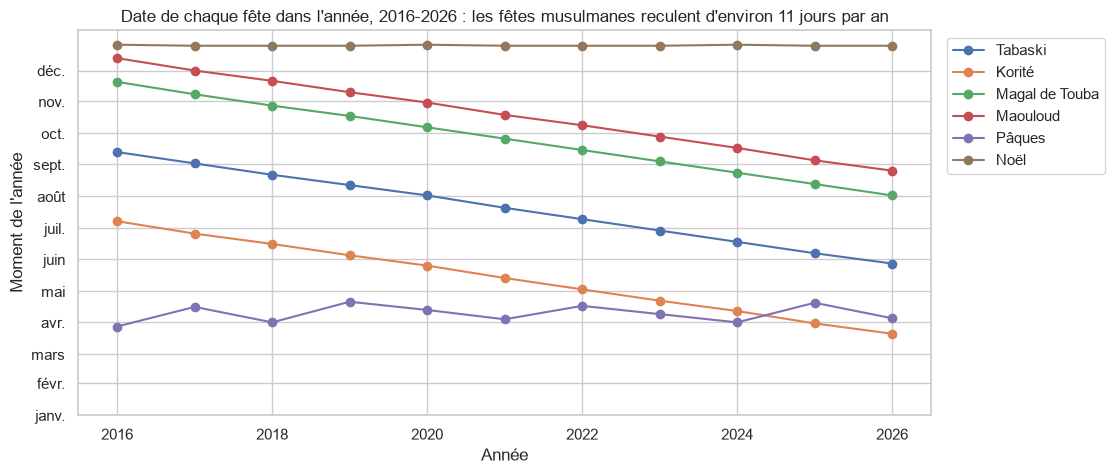

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
for evenement in ["Tabaski", "Korité", "Magal de Touba", "Maouloud", "Pâques", "Noël"]:
    occ = calendrier[(calendrier["evenement"] == evenement) & (calendrier["annee"] >= 2016)]
    ax.plot(occ["annee"], occ["date_debut"].dt.dayofyear, marker="o", label=evenement)

# Axe vertical gradué en mois plutôt qu'en numéro de jour
debuts_mois = pd.date_range("2021-01-01", periods=12, freq="MS")
ax.set_yticks(debuts_mois.dayofyear)
ax.set_yticklabels(["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."])
ax.set_title("Date de chaque fête dans l'année, 2016-2026 : les fêtes musulmanes reculent d'environ 11 jours par an")
ax.set_xlabel("Année")
ax.set_ylabel("Moment de l'année")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
sauver_figure(fig, "p2_dates_fetes_par_annee")
plt.show()

le pic de ventes de moutons change de mois

Figure enregistrée : p2_ventes_mouton_mois_annee.png


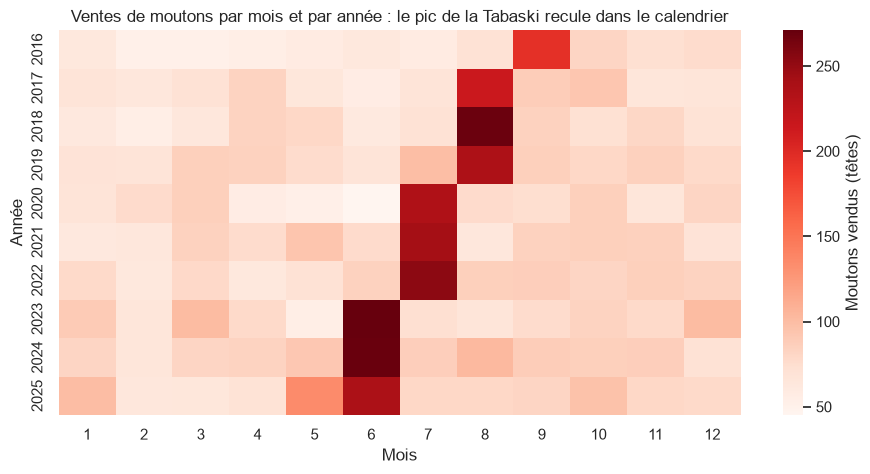

Mois du pic de ventes de moutons : {2016: 9, 2017: 8, 2018: 8, 2019: 8, 2020: 7, 2021: 7, 2022: 7, 2023: 6, 2024: 6, 2025: 6}


In [16]:
mouton = ventes[ventes["categorie"] == "betail_mouton"]
mouton_mois = (mouton.groupby([mouton["date"].dt.year.rename("annee"), mouton["date"].dt.month.rename("mois")])
               ["quantite"].sum().unstack())

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(mouton_mois, cmap="Reds", ax=ax, cbar_kws={"label": "Moutons vendus (têtes)"})
ax.set_title("Ventes de moutons par mois et par année : le pic de la Tabaski recule dans le calendrier")
ax.set_xlabel("Mois")
ax.set_ylabel("Année")
sauver_figure(fig, "p2_ventes_mouton_mois_annee")
plt.show()

# Mois du pic chaque année
print("Mois du pic de ventes de moutons :", mouton_mois.idxmax(axis=1).to_dict())

In [ ]:
### 2.3 Ajout des variables d'événement aux ventes

fusion et sauvegarde

In [17]:
if peut_recharger(chemin_parquet("ventes_evenements")):
    ventes_evt = pd.read_parquet(chemin_parquet("ventes_evenements"))
    print("Ventes + variables d'événement rechargées")
else:
    # Une ligne de vente reçoit les variables de sa date (plusieurs ventes pour une même date)
    ventes_evt = ventes.merge(vars_calendrier, on="date", how="left", validate="many_to_one")
    ventes_evt.to_parquet(chemin_parquet("ventes_evenements"), index=False)
    print("Ventes + variables d'événement calculées et sauvegardées")

print("Dimensions :", ventes_evt.shape)
print("Valeurs manquantes après fusion :", int(ventes_evt.isna().sum().sum()))
print("Mémoire :", round(ventes_evt.memory_usage(deep=True).sum() / 1e6, 1), "Mo")

Ventes + variables d'événement calculées et sauvegardées
Dimensions : (530490, 28)
Valeurs manquantes après fusion : 0
Mémoire : 43.0 Mo


### Conclusion de la partie 2

La fonction `variables_calendrier` produit 19 variables pour chaque date : `av_` et `ap_` pour 9 fêtes, plafonnées à 60 jours, et l'indicateur `ramadan`, qui compte 29 ou 30 jours par an. Elle utilise `pd.merge_asof` vers l'avant et vers l'arrière sur les 4 018 dates de 2016-2026, sans boucle sur les ventes. Le résultat est ensuite fusionné aux 530 490 lignes de ventes (28 colonnes, aucune valeur manquante). Le plafond traite aussi les bords du calendrier : il n'y a pas d'occurrence précédente début 2016 ni d'occurrence suivante fin 2026. Selon le calendrier, **la Tabaski recule de 10 à 12 jours chaque année** (10,7 en moyenne, soit 354-355 jours entre deux Tabaski) : elle passe du 12 septembre 2016 au 28 mai 2026, soit 108 jours plus tôt. Le pic de ventes de moutons suit ce recul : septembre en 2016, août en 2017-2019, juillet en 2020-2022, juin en 2023-2025. **Une variable « mois » ne suffit donc pas** : apprise sur 2016-2023, elle associerait l'effet de la Tabaski à juillet-août, alors qu'en 2025 il tombe en juin. Elle coupe aussi une fenêtre d'achat entre deux mois, comme en 2025, où une partie des achats tombe fin mai. Seule la distance en jours à la fête, recalculée chaque année depuis le calendrier, suit ce déplacement. Les fêtes chrétiennes ne bougent pas de la même façon : Noël est fixe, et Pâques varie entre fin mars et fin avril.